Cloning into '/content/urdu-asr-subtitles'...
remote: Enumerating objects: 40, done.
remote: Counting objects: 100% (40/40), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 40 (delta 11), reused 34 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (40/40), 1.91 MiB | 30.99 MiB/s, done.
Resolving deltas: 100% (11/11), done.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
datasets version: 3.6.0


README.md:   0%|          | 0.00/386k [00:00<?, ?B/s]

parquet-data/ur_pk/train-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B / 1.60GB            

parquet-data/ur_pk/train-00000-of-00001.(…): downloading bytes:           |  0.00B            

parquet-data/ur_pk/validation-00000-of-0(…): reconstructing file:   0%|          |  0.00B /  174MB            

parquet-data/ur_pk/validation-00000-of-0(…): downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/2109 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/267 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/299 [00:00<?, ? examples/s]

{'name': 'train', 'num_examples': 2109, 'hours': 7.03, 'columns': ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id']}
{'name': 'validation', 'num_examples': 267, 'hours': 0.76, 'columns': ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id']}
{'name': 'test', 'num_examples': 299, 'hours': 0.81, 'columns': ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id']}

Columns: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id']
ID: 72
Transcription (saaf text): مشہور یونانی وُکلاء سیکس کیچاجیوگلو اور جارج نکولاپولس کو کوریڈیلس کی ایھنز کی جیل میں قید کرکے رکھا گیا ہے کیونکہ وہ مکاری اور بدعنوانی کے مرتکب پائے گئے تھے
Raw transcription: مشہور یونانی وُکلاء، سیکس کیچاجیوگلو اور جارج نکولاپولس کو کوریڈیلس

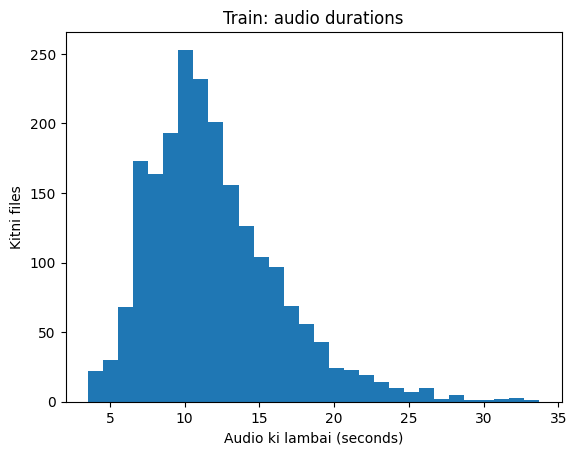

Sab se chhoti: 3.5s, sab se lambi: 33.7s

Unique characters: 112
Sab se common 15: [(' ', 53888), ('ا', 23771), ('ی', 21887), ('ک', 14082), ('ر', 13468), ('و', 13128), ('ے', 10860), ('ن', 10483), ('ہ', 10073), ('م', 8918), ('ت', 7731), ('س', 7665), ('ل', 6996), ('ب', 5123), ('ں', 4855)]
Sab se rare 10: [('ٖ', 2), ('x', 2), ('j', 2), ('h', 2), ('٪', 1), ('—', 1), ('ه', 1), ('ٴ', 1), ('ي', 1), ('r', 1)]

Avg alfaaz per sentence: 26.5
Train/test overlap sentences: 0


In [1]:
# ============================================================
# STEP 3: FLEURS URDU DATASET EXPLORE (Colab, ek cell)
# ============================================================
import os, sys

# ---------- 1. Repo ka latest code ----------
REPO_URL = "https://github.com/FatimaaShaheen/urdu-asr-subtitles.git"
REPO_DIR = "/content/urdu-asr-subtitles"
if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}
else:
    !cd {REPO_DIR} && git pull

# ---------- 2. Libraries (datasets<4 zaroori hai) ----------
!pip install -q "datasets<4" librosa soundfile

os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.append(REPO_DIR)

# ---------- 3. Apne functions ----------
import datasets
print("datasets version:", datasets.__version__)   # 3.x hona chahiye

from src.data.load_dataset import load_fleurs_urdu, summary, char_vocab
from IPython.display import Audio, display
import matplotlib.pyplot as plt

# ---------- 4. Teeno splits ----------
train = load_fleurs_urdu("train")
val   = load_fleurs_urdu("validation")
test  = load_fleurs_urdu("test")
for name, d in [("train", train), ("validation", val), ("test", test)]:
    print(summary(d, name))

# ---------- 5. Ek example andar se ----------
s = train[0]
print("\nColumns:", train.column_names)
print("ID:", s["id"])
print("Transcription (saaf text):", s["transcription"])
print("Raw transcription:", s["raw_transcription"])
print("Sampling rate:", s["audio"]["sampling_rate"])
print("Audio array shape:", s["audio"]["array"].shape)
display(Audio(s["audio"]["array"], rate=s["audio"]["sampling_rate"]))

# ---------- 6. Audio ki lambai ka histogram ----------
durations = [n / 16000 for n in train["num_samples"]]
plt.hist(durations, bins=30)
plt.xlabel("Audio ki lambai (seconds)")
plt.ylabel("Kitni files")
plt.title("Train: audio durations")
plt.show()
print(f"Sab se chhoti: {min(durations):.1f}s, sab se lambi: {max(durations):.1f}s")

# ---------- 7. Characters ki vocabulary ----------
vocab = char_vocab(train)
print("\nUnique characters:", len(vocab))
print("Sab se common 15:", vocab.most_common(15))
print("Sab se rare 10:", vocab.most_common()[-10:])

# ---------- 8. Text ki lambai ----------
lens = [len(t.split()) for t in train["transcription"]]
print(f"\nAvg alfaaz per sentence: {sum(lens)/len(lens):.1f}")

# ---------- 9. Data leakage check ----------
overlap = set(train["transcription"]) & set(test["transcription"])
print("Train/test overlap sentences:", len(overlap))